# 04 · Models and evaluation
**Owner:** Kasula Lalithendra

1. **train**: tune Logistic Regression, Random Forest and Gradient Boosting with GroupKFold (by premise)
2. **validation**: pick the best model
3. **test**: evaluate once (precision, recall, F1, confusion matrix, confidence interval, error analysis)

In [1]:
# ─── IMPORTS ─────
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")
from c2c.features import FEATURES

In [2]:
# ─── LOAD DATA ─────
data = pd.read_csv("../data/processed/features.csv")

train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]
test = data[data["split"] == "test"]

y_train = train["label"]
y_val = validation["label"]
y_test = test["label"]

print(train.shape, validation.shape, test.shape)

(35340, 24) (1026, 24) (1162, 24)


In [3]:
# ─── STEP 1: BUILD THE FEATURES (TF-IDF + STRUCTURED) ─────
# everything is fitted on train only, then applied to validation and test
tfidf_premise = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
tfidf_hypothesis = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
scaler = StandardScaler()

X_train = np.hstack([tfidf_premise.fit_transform(train["premise"]).toarray(),
                     tfidf_hypothesis.fit_transform(train["hypothesis"]).toarray(),
                     scaler.fit_transform(train[FEATURES])])
X_val = np.hstack([tfidf_premise.transform(validation["premise"]).toarray(),
                   tfidf_hypothesis.transform(validation["hypothesis"]).toarray(),
                   scaler.transform(validation[FEATURES])])
X_test = np.hstack([tfidf_premise.transform(test["premise"]).toarray(),
                    tfidf_hypothesis.transform(test["hypothesis"]).toarray(),
                    scaler.transform(test[FEATURES])])

print(X_train.shape, X_val.shape, X_test.shape)

(35340, 256) (1026, 256) (1162, 256)


In [4]:
# ─── STEP 2: LOGISTIC REGRESSION ─────
# GroupKFold keeps all rows of a premise in the same fold
# class_weight="balanced" makes the rare valid class count as much as the invalid one
lr_search = GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced"),
                         {"C": [0.1, 1, 10]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
lr_search.fit(X_train, y_train, groups=train["premise_id"])
print(lr_search.best_params_, round(lr_search.best_score_, 3))

{'C': 10} 0.926


In [5]:
# ─── STEP 3: RANDOM FOREST ─────
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
                         {"max_depth": [None, 20], "min_samples_leaf": [1, 5]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
rf_search.fit(X_train, y_train, groups=train["premise_id"])
print(rf_search.best_params_, round(rf_search.best_score_, 3))

{'max_depth': 20, 'min_samples_leaf': 1} 0.935


In [6]:
# ─── STEP 4: GRADIENT BOOSTING ─────
gb_search = GridSearchCV(HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
                         {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
gb_search.fit(X_train, y_train, groups=train["premise_id"])
print(gb_search.best_params_, round(gb_search.best_score_, 3))

{'learning_rate': 0.1, 'max_leaf_nodes': 31} 0.949


In [7]:
# ─── STEP 5: PICK THE MODEL ON VALIDATION ─────
lr_val_pred = lr_search.predict(X_val)
rf_val_pred = rf_search.predict(X_val)
gb_val_pred = gb_search.predict(X_val)

val_results = pd.DataFrame({
    "precision": [precision_score(y_val, lr_val_pred), precision_score(y_val, rf_val_pred), precision_score(y_val, gb_val_pred)],
    "recall": [recall_score(y_val, lr_val_pred), recall_score(y_val, rf_val_pred), recall_score(y_val, gb_val_pred)],
    "F1": [f1_score(y_val, lr_val_pred), f1_score(y_val, rf_val_pred), f1_score(y_val, gb_val_pred)],
}, index=["Logistic Regression", "Random Forest", "Gradient Boosting"])
val_results.round(3)

,precision,recall,F1
Logistic Regression,0.889,0.868,0.878
Random Forest,0.893,0.969,0.929
Gradient Boosting,0.955,0.814,0.879


In [8]:
# the model with the best validation F1 is our final model
models = {"Logistic Regression": lr_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}
best_name = val_results["F1"].idxmax()
best_model = models[best_name]
best_name

'Random Forest'

In [9]:
# ─── STEP 6: FINAL RESULTS ON TEST ─────
lr_test_pred = lr_search.predict(X_test)
rf_test_pred = rf_search.predict(X_test)
gb_test_pred = gb_search.predict(X_test)
rule_pred = (test["mec_support"] == 1).astype(int)   # no learning: valid if PC says it must be true

test_results = pd.DataFrame({
    "precision": [precision_score(y_test, lr_test_pred), precision_score(y_test, rf_test_pred),
                  precision_score(y_test, gb_test_pred), precision_score(y_test, rule_pred)],
    "recall": [recall_score(y_test, lr_test_pred), recall_score(y_test, rf_test_pred),
               recall_score(y_test, gb_test_pred), recall_score(y_test, rule_pred)],
    "F1": [f1_score(y_test, lr_test_pred), f1_score(y_test, rf_test_pred),
           f1_score(y_test, gb_test_pred), f1_score(y_test, rule_pred)],
}, index=["Logistic Regression", "Random Forest", "Gradient Boosting", "Symbolic rule (no learning)"])
test_results.round(3)

,precision,recall,F1
Logistic Regression,0.922,0.983,0.952
Random Forest,0.927,0.989,0.957
Gradient Boosting,0.927,0.989,0.957
Symbolic rule (no learning),0.922,0.983,0.952


The model was chosen on validation, so we keep it even if another one scores higher on test.

In [10]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

In [11]:
# ─── STEP 7: CONFUSION MATRIX ─────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

In [12]:
# True Negatives:
tn

np.int64(968)

In [13]:
# False Positives:
fp

np.int64(14)

In [14]:
# False Negatives:
fn

np.int64(2)

In [15]:
# True Positives:
tp

np.int64(178)

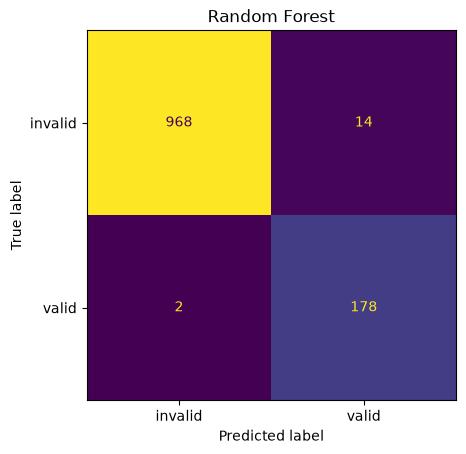

In [16]:
ConfusionMatrixDisplay(cm, display_labels=["invalid", "valid"]).plot(colorbar=False)
plt.title(best_name)
plt.savefig("../report/figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# ─── STEP 8: 95% CONFIDENCE INTERVAL (BOOTSTRAP) ─────
# rows from the same premise are not independent, so we resample whole premises 1000 times
results = test[["premise_id", "template", "num_variables", "hypothesis", "label"]].copy()
results["pred"] = y_pred
results["proba"] = y_proba

rng = np.random.default_rng(42)
premises = results["premise_id"].unique()
f1_scores = []
for i in range(1000):
    chosen = rng.choice(premises, size=len(premises))
    sample = pd.DataFrame({"premise_id": chosen}).merge(results, on="premise_id")
    f1_scores.append(f1_score(sample["label"], sample["pred"]))

print("test F1:", round(f1_score(y_test, y_pred), 3))
print("95% CI: ", np.percentile(f1_scores, [2.5, 97.5]).round(3))

test F1: 0.957
95% CI:  [0.921 0.982]


In [18]:
# ─── STEP 9: ERROR ANALYSIS ─────
results["wrong"] = results["pred"] != results["label"]
results["false_alarm"] = (results["pred"] == 1) & (results["label"] == 0)
results["miss"] = (results["pred"] == 0) & (results["label"] == 1)

# errors by hypothesis type
results.groupby("template")[["wrong", "false_alarm", "miss"]].sum()

,wrong,false_alarm,miss
template,,,
child,0,0,0
has_collider,3,3,0
has_confounder,2,0,2
non-child descendant,2,2,0
non-parent ancestor,1,1,0
parent,8,8,0


* "child" claims are never valid and the model makes no mistakes on them.
* Half of the 16 mistakes are false alarms on "parent" claims: every fitting DAG has the edge X → Y, but the
  label is 0. These are the label disagreements found in notebook 02.

In [19]:
# errors by number of variables (train only had 5-6)
results.groupby("num_variables")["wrong"].agg(["count", "sum", "mean"])

,count,sum,mean
num_variables,,,
2,6,0,0.000000
3,48,0,0.000000
4,72,1,0.013889
5,514,3,0.005837
6,522,12,0.022989


The small graphs (2–4 variables) have an error rate as low as the big ones (1 mistake in 126 rows) even though
train never had them, because the structured features come from the parser and PC, not from memorising sentences.

In [20]:
# the most confident mistakes
results[results["wrong"]].sort_values("proba", ascending=False).head()

,premise_id,template,num_variables,hypothesis,label,pred,proba,wrong,false_alarm,miss
37422,2375,parent,6,B directly causes E.,0,1,0.978894,True,True,False
37071,2371,parent,6,B directly causes F.,0,1,0.949814,True,True,False
37500,2375,parent,6,A directly causes F.,0,1,0.903733,True,True,False
36687,2364,parent,5,A directly causes E.,0,1,0.829359,True,True,False
37176,2356,parent,6,B directly causes D.,0,1,0.814718,True,True,False


In [21]:
# ─── STEP 10: SAVE TEST PREDICTIONS FOR NOTEBOOK 05 ─────
test[["premise_id", "hypothesis", "template", "relation", "x", "y", "label"]].assign(proba=y_proba, pred=y_pred).to_csv(
    "../data/processed/test_predictions.csv", index=False)